# VideoMAE masked reconstruction on DSERT-RoLL's 2D cameras

This notebook uses only the **camera modalities** (RGB, thermal, event; left cameras by default) and asks two questions:

**A. Within one camera.** Can pretrained VideoMAE fill in masked space-time patches of a clip from each camera, as in its own pretraining? It was pretrained only on RGB video (Kinetics-400), so thermal and event show how well that transfers. No training.

**B. Across cameras.** Can VideoMAE reconstruct a whole hidden camera from a visible one, e.g. thermal from RGB? VideoMAE was **not** built for this: it fills gaps within one video and has never learned cross-sensor mappings. So we test it:
- **as-is** (zero-shot), to show what the pretrained model does, and
- **after a short fine-tune** on DSERT-RoLL train sequences, which teaches the mapping.

To stay inside VideoMAE's unmodified 224×224 input, each frame for part B is a **stack**: source camera in the top half (112×224), target camera in the bottom half (112×224). All bottom-half tokens are masked, so the decoder must predict the target from the source alone. The 2:1 halves roughly keep the driving cameras' wide aspect.

**Metric.** VideoMAE's own objective: mean squared error on **per-patch-normalized** pixels of the masked patches (each 2×16×16 tube is normalized to zero mean and unit variance per channel). This scores *structure* (edges, shapes, texture), not absolute brightness. **1.0 = predicting a flat patch**; lower is better. Results are averaged per sequence, then over sequences, on the official val split. They're also broken down by weather.

**Baselines for B:** flat patch (1.0 by construction), and *copy*: use the grayscale source patch at the same spot (and its inverse) as the prediction. Copy is strong when the cameras are pixel-aligned and the modalities look alike.

**Lazy streaming.** Nothing is downloaded up front. A sequence is streamed only when a training or evaluation step first needs it, and only for the cameras that step uses. Streaming stops once `MAX_CLIPS_PER_SEQ` clips exist, and the clips are saved per sequence and camera in `CACHE_DIR`, so nothing is fetched twice, even across sessions. The table at the end lists what was streamed and why.

Put `dsert_stream.py` next to this notebook. A CUDA GPU is strongly recommended for the fine-tune (part B2).

In [1]:
# %pip install -U huggingface_hub "transformers>=4.40" torch numpy pillow pandas matplotlib
import os, sys, json, time, math, random, collections, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn.functional as F
from huggingface_hub import HfFileSystem

DSERT_STREAM_DIR = "."
sys.path.insert(0, os.path.abspath(DSERT_STREAM_DIR))
from dsert_stream import DsertStream, REPO

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
AMP_DTYPE = (torch.bfloat16 if DEVICE == "cuda" and torch.cuda.is_bf16_supported() else
             torch.float16 if DEVICE == "cuda" else None)
print("device:", DEVICE, "autocast:", AMP_DTYPE)

/home/nince/venvs/myenv/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda autocast: torch.bfloat16


In [2]:
os.environ["HF_TOKEN"] = ""

## Configuration

In [3]:
CHECKPOINT = "MCG-NJU/videomae-base"   # must be a *pretraining* checkpoint (has the decoder); Kinetics-fine-tuned ones don't

MODALITIES = ["rgb_l", "thermal_l", "event_l"]     # 2D cameras only
PAIRS = [("rgb_l", "thermal_l"), ("thermal_l", "rgb_l"),   # (visible source, hidden target) for part B
         ("rgb_l", "event_l"), ("event_l", "rgb_l")]
SELF_MASK_RATIOS = [0.75, 0.9]          # part A tube-mask ratios (VideoMAE pretrained at 0.9)

SEQ_PER_WEATHER = {"train": 4, "val": 2}
CLIP_LEN, FRAME_STEP, CLIP_STRIDE, MAX_CLIPS_PER_SEQ = 16, 1, 16, 8
HALF_HW = (112, 224)                    # each camera is cached at this size (H, W)

# event rendering
EVENT_SENSOR_HW = None                  # (H, W) of the event sensor; None = infer from the first file
EVENT_CLIP_COUNT = 2.0                  # |signed events per cached pixel| that maps to full white/black

# fine-tuning (part B2), one model per pair
FT_STEPS, FT_BATCH, FT_LR, FT_WARMUP, FT_EVAL_EVERY = 600, 4, 1e-4, 50, 100
EVAL_BATCH = 8
CACHE_DIR = "dsert_2d_cache"
SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

## Pick sequences (weather-stratified, official split)

In [4]:
fs = HfFileSystem()

def read_split(name):
    text = fs.cat_file(f"{REPO}/split/{name}.txt").decode()
    return [l.strip().strip("/") for l in text.splitlines() if l.strip()]

def stratified(seqs, k, seed):
    by_w = collections.defaultdict(list)
    for s in seqs:
        by_w[s.split("/")[0]].append(s)
    rng = random.Random(seed)
    return [s for w in sorted(by_w) for s in rng.sample(by_w[w], min(k, len(by_w[w])))]

selected = {sp: stratified(read_split(sp), SEQ_PER_WEATHER[sp], SEED) for sp in ("train", "val")}
for sp, seqs in selected.items():
    print(sp, len(seqs), dict(collections.Counter(s.split("/")[0] for s in seqs)))

train 24 {'Clear': 4, 'Fog': 4, 'Heavy_Rain': 4, 'Heavy_Snow': 4, 'Light_Rain': 4, 'Light_Snow': 4}
val 12 {'Clear': 2, 'Fog': 2, 'Heavy_Rain': 2, 'Heavy_Snow': 2, 'Light_Rain': 2, 'Light_Snow': 2}


## Inspect one frame of each camera
The event and thermal `.npz` contents aren't documented, so check what arrived. The event renderer below handles `x/y/p` arrays, an N×4 event list, or a dense frame. If it guesses wrong, adjust `event_signed()`.

In [5]:
first = next(iter(DsertStream(sequences=selected["val"][:1], sensors=MODALITIES)))
for m in MODALITIES:
    v = first["sensors"][m]
    if isinstance(v, dict):
        print(m, {k: (a.shape, a.dtype.name, float(np.min(a)) if a.size else None, float(np.max(a)) if a.size else None)
                  for k, a in v.items()})
    else:
        print(m, v.shape, v.dtype)

rgb_l (1200, 1920, 3) uint8
thermal_l (384, 480, 3) uint8
event_l {'event': ((1620081, 4), 'uint32', 0.0, 412394.0)}


## Decode cameras to images and cache clips

In [6]:
def _resize_float(a, hw, box=False):
    im = Image.fromarray(np.ascontiguousarray(a, dtype=np.float32), mode="F")
    return np.asarray(im.resize((hw[1], hw[0]), Image.BOX if box else Image.BILINEAR), dtype=np.float32)

def rgb_frame(x):
    return np.asarray(Image.fromarray(np.asarray(x)[..., :3]).resize((HALF_HW[1], HALF_HW[0]), Image.BILINEAR))

def thermal_raw(x):
    # -> float32 HALF_HW; normalized later per clip so brightness doesn't flicker
    if isinstance(x, dict):
        x = max((v for v in x.values() if getattr(v, "ndim", 0) >= 2), key=lambda v: v.size)
    x = np.asarray(x, dtype=np.float32)
    if x.ndim == 3:
        x = x.mean(axis=0 if x.shape[0] in (1, 3) and x.shape[-1] not in (1, 3) else -1)
    return _resize_float(x, HALF_HW)

def event_signed(d):
    # Signed event count image at sensor resolution (positive minus negative events).
    global EVENT_SENSOR_HW
    keys = {k.lower(): k for k in d}
    get = lambda *ns: next((np.asarray(d[keys[n]]) for n in ns if n in keys), None)
    x, y, p = get("x", "xs"), get("y", "ys"), get("p", "ps", "pol", "polarity")
    if x is None:
        a = max((np.asarray(v) for v in d.values()), key=lambda v: v.size)
        if a.ndim == 2 and a.shape[1] in (3, 4) and a.shape[0] > 16:          # event list N x (x,y,t,p) in some order
            cols = list(a.T.astype(np.float64))
            pi = next((i for i, c in enumerate(cols) if len(np.unique(c[:5000])) <= 2), None)
            rest = [i for i in range(len(cols)) if i != pi]
            if len(rest) == 3:                                               # drop the timestamp (largest values)
                rest.remove(max(rest, key=lambda i: cols[i].max()))
            x, y = cols[rest[0]], cols[rest[1]]
            p = cols[pi] if pi is not None else np.ones_like(x)
        else:                                                                # already a dense frame / voxel grid
            a = a.astype(np.float32)
            if a.ndim == 3:
                small = 0 if a.shape[0] <= a.shape[-1] else -1
                a = (a[0] - a[1]) if a.shape[small] == 2 and small == 0 else a.sum(axis=small)
            return a
    x, y = np.asarray(x, np.float64), np.asarray(y, np.float64)
    p = np.where(np.asarray(p) > 0, 1.0, -1.0) if p is not None else np.ones_like(x)
    if EVENT_SENSOR_HW is None:
        EVENT_SENSOR_HW = (int(np.ceil(y.max())) + 1, int(np.ceil(x.max())) + 1) if x.size else (480, 640)
        print("event sensor size inferred as", EVENT_SENSOR_HW)
    H, W = EVENT_SENSOR_HW
    xi, yi = np.clip(np.round(x).astype(int), 0, W - 1), np.clip(np.round(y).astype(int), 0, H - 1)
    img = np.zeros((H, W), np.float32)
    np.add.at(img, (yi, xi), p.astype(np.float32))
    return img

def event_frame(d):
    s = event_signed(d) if isinstance(d, dict) else np.asarray(d, np.float32)
    area = (s.shape[0] * s.shape[1]) / (HALF_HW[0] * HALF_HW[1])
    s = _resize_float(s, HALF_HW, box=True) * area                     # sum-pool to cache size
    g = 0.5 + 0.5 * np.clip(s / EVENT_CLIP_COUNT, -1, 1)              # gray = no events
    return np.repeat((g * 255).astype(np.uint8)[..., None], 3, -1)

def finish_clip(mod, frames):
    if mod.startswith("thermal"):
        a = np.stack(frames)
        lo, hi = np.percentile(a, (1, 99))
        a = (np.clip((a - lo) / max(hi - lo, 1e-6), 0, 1) * 255).astype(np.uint8)
        return np.repeat(a[..., None], 3, -1)
    return np.stack(frames)

DECODE = {"rgb": rgb_frame, "thermal": thermal_raw, "event": event_frame}

def stream_clips(seq, mods):
    # Stream ONE sequence for the given cameras only, and stop as soon as MAX_CLIPS_PER_SEQ clips exist.
    out, buf, pos = {m: [] for m in mods}, {m: [] for m in mods}, 0
    for s in DsertStream(sequences=[seq], sensors=mods):
        pos += 1
        if (pos - 1) % FRAME_STEP:
            continue
        for m in mods:
            buf[m].append(DECODE[m.split("_")[0]](s["sensors"][m]))
        if len(buf[mods[0]]) == CLIP_LEN:
            for m in mods:
                out[m].append(finish_clip(m, buf[m]))
                buf[m] = buf[m][CLIP_STRIDE:]
            if len(out[mods[0]]) >= MAX_CLIPS_PER_SEQ:
                break                                   # rest of the sequence is never downloaded
    return {m: np.stack(v) if v else np.zeros((0, CLIP_LEN, *HALF_HW, 3), np.uint8) for m, v in out.items()}

CONFIG_KEY = hashlib.md5(json.dumps([CLIP_LEN, FRAME_STEP, CLIP_STRIDE, MAX_CLIPS_PER_SEQ, HALF_HW,
                                     EVENT_CLIP_COUNT, EVENT_SENSOR_HW]).encode()).hexdigest()[:8]

class ClipStore:
    # Lazy per-(sequence, camera) clip cache.
    # get(seq, cameras) returns {camera: uint8 array (n_clips, T, H, W, 3)}. A camera of a sequence is
    # streamed from Hugging Face only the first time a step asks for it; the clips are saved to disk
    # and memory-mapped, so later steps (and later sessions) reuse them without downloading.
    def __init__(self, cache_dir=CACHE_DIR):
        self.dir = cache_dir
        os.makedirs(cache_dir, exist_ok=True)
        self.mem, self.log = {}, []

    def _path(self, seq, mod):
        return os.path.join(self.dir, f"{seq.replace('/', '__')}__{mod}__{CONFIG_KEY}.npy")

    def has(self, seq, mod):
        return (seq, mod) in self.mem or os.path.exists(self._path(seq, mod))

    def get(self, seq, mods, reason=""):
        missing = [m for m in mods if not self.has(seq, m)]
        if missing:
            t = time.perf_counter()
            clips = stream_clips(seq, missing)
            for m in missing:
                tmp = self._path(seq, m) + ".tmp.npy"
                np.save(tmp, clips[m]); os.replace(tmp, self._path(seq, m))
            secs = time.perf_counter() - t
            n = len(clips[missing[0]])
            self.log.append({"sequence": seq, "cameras": ", ".join(missing), "clips": n,
                             "seconds": round(secs, 1), "first needed for": reason})
            print(f"  streamed {seq} [{', '.join(missing)}] for {reason}: {n} clips in {secs:.0f}s")
        for m in mods:
            if (seq, m) not in self.mem:
                self.mem[(seq, m)] = np.load(self._path(seq, m), mmap_mode="r")
        out = {m: self.mem[(seq, m)] for m in mods}
        n = min(len(a) for a in out.values())            # guard against a camera missing frames
        return {m: a[:n] for m, a in out.items()}

store = ClipStore()
print("nothing streamed yet; cache dir:", os.path.abspath(CACHE_DIR))

nothing streamed yet; cache dir: /home/nince/dsert_2d_cache


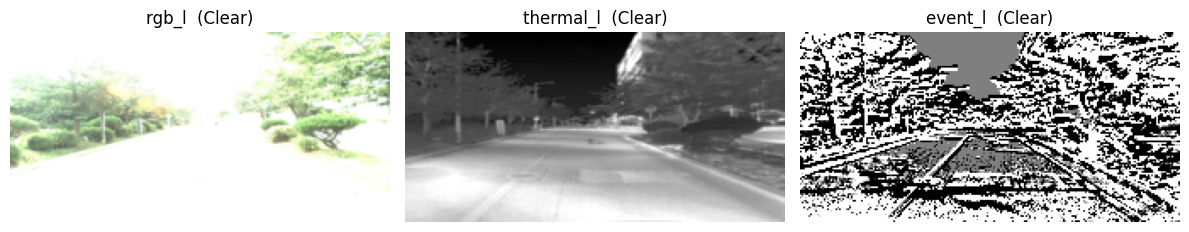

In [7]:
# Look at one clip per camera (middle frame). This streams the first val sequence, which evaluation needs anyway.
seq0 = selected["val"][0]
c0 = store.get(seq0, MODALITIES, "preview")
fig, axes = plt.subplots(1, len(MODALITIES), figsize=(4 * len(MODALITIES), 2.4))
for ax, m in zip(np.atleast_1d(axes), MODALITIES):
    if len(c0[m]):
        ax.imshow(c0[m][0, CLIP_LEN // 2])
    ax.set_title(f"{m}  ({seq0.split('/')[0]})"); ax.axis("off")
plt.tight_layout(); plt.show()

## VideoMAE patch, mask and loss helpers
These mirror `VideoMAEForPreTraining`'s internal target exactly (token order t→h→w; patch vector order tubelet→row→col→channel). The self-check below confirms it against the model's own loss.

In [8]:
from transformers import VideoMAEForPreTraining

TS, PS, IMG = 2, 16, 224
NT, NH, NW = CLIP_LEN // TS, IMG // PS, IMG // PS            # 8, 14, 14
N_TOK = NT * NH * NW                                         # 1568
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 1, 3, 1, 1)

def to01(u8):                      # (B,T,H,W,3) uint8 numpy -> (B,T,3,H,W) float on DEVICE
    return torch.from_numpy(np.ascontiguousarray(u8)).to(DEVICE).permute(0, 1, 4, 2, 3).float() / 255

def stack_halves(src01, tgt01):    # source on top, target below -> (B,T,3,224,224)
    return torch.cat([src01, tgt01], dim=3)

def full_frame(x01):               # one camera stretched to 224x224 for part A
    B, T, C, H, W = x01.shape
    return F.interpolate(x01.reshape(B * T, C, H, W), size=(IMG, IMG), mode="bilinear",
                         align_corners=False).reshape(B, T, C, IMG, IMG)

def to_pixel_values(x01):
    return (x01 - MEAN.to(x01.device)) / STD.to(x01.device)

def patchify(x01):                 # (B,T,C,H,W) -> (B,N,TS*PS*PS,C)
    B, T, C, H, W = x01.shape
    x = x01.reshape(B, T // TS, TS, C, H // PS, PS, W // PS, PS).permute(0, 1, 4, 6, 2, 5, 7, 3)
    return x.reshape(B, (T // TS) * (H // PS) * (W // PS), TS * PS * PS, C)

def unpatchify(p, T=CLIP_LEN, H=IMG, W=IMG):
    B, C = p.shape[0], p.shape[-1]
    x = p.reshape(B, T // TS, H // PS, W // PS, TS, PS, PS, C).permute(0, 1, 4, 7, 2, 5, 3, 6)
    return x.reshape(B, T, C, H, W)

def patch_stats(p):
    return p.mean(-2, keepdim=True), p.var(-2, unbiased=True, keepdim=True).sqrt() + 1e-6

def norm_targets(x01):             # (B,N,1536), the normalized-pixel target VideoMAE trains on
    p = patchify(x01)
    mu, sd = patch_stats(p)
    return ((p - mu) / sd).flatten(2)

def tube_mask(B, ratio, gen=None):
    k = int(round(ratio * NH * NW))
    scores = torch.rand(B, NH * NW, generator=gen)
    m = torch.zeros(B, NH * NW, dtype=torch.bool)
    m.scatter_(1, scores.argsort(1)[:, :k], True)
    return m[:, None].expand(B, NT, NH * NW).reshape(B, N_TOK)

def bottom_half_mask(B):
    m = torch.zeros(NH, NW, dtype=torch.bool)
    m[NH // 2:] = True
    return m.flatten()[None, None].expand(B, NT, NH * NW).reshape(B, N_TOK).clone()

def per_sample_nmse(pred, x01, mask):          # pred: (B, n_masked, 1536)
    B = x01.shape[0]
    tgt = norm_targets(x01)[mask.to(x01.device)].reshape(B, -1, TS * PS * PS * 3)
    return ((pred.float() - tgt) ** 2).mean((1, 2))

def run(model, x01, mask):
    with torch.autocast(DEVICE, dtype=AMP_DTYPE, enabled=AMP_DTYPE is not None):
        return model(pixel_values=to_pixel_values(x01), bool_masked_pos=mask.to(x01.device)).logits

base = VideoMAEForPreTraining.from_pretrained(CHECKPOINT).to(DEVICE).eval()
print(f"{CHECKPOINT}: {sum(p.numel() for p in base.parameters())/1e6:.0f}M params, "
      f"norm_pix_loss={base.config.norm_pix_loss}")

MCG-NJU/videomae-base: 94M params, norm_pix_loss=True


### Self-check: our loss must equal VideoMAE's built-in loss

In [9]:
with torch.no_grad():
    x = full_frame(to01(store.get(selected["val"][0], [MODALITIES[0]], "self-check")[MODALITIES[0]][:2]))
    m = tube_mask(len(x), 0.9, torch.Generator().manual_seed(0))
    out = base(pixel_values=to_pixel_values(x), bool_masked_pos=m.to(DEVICE))      # fp32, no autocast
    ours = per_sample_nmse(out.logits, x, m).mean()
print(f"model loss {out.loss.item():.5f}   ours {ours.item():.5f}")
assert base.config.norm_pix_loss, "this notebook assumes a norm_pix_loss checkpoint"
assert abs(out.loss.item() - ours.item()) < 1e-3 * max(1.0, out.loss.item()), "patch/mask order mismatch"
print("OK: metric matches VideoMAE's objective")

/tmp/nince-tmpdir-qY165Y/ipykernel_3858596/1571732284.py:10: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at ../torch/csrc/utils/tensor_numpy.cpp:206.)
  return torch.from_numpy(np.ascontiguousarray(u8)).to(DEVICE).permute(0, 1, 4, 2, 3).float() / 255


model loss 0.47399   ours 0.47399
OK: metric matches VideoMAE's objective


## Evaluation helpers

In [10]:
def make_x(c, idx, mode, mod=None, src=None, tgt=None):
    if mode == "self":
        return full_frame(to01(c[mod][idx]))
    return stack_halves(to01(c[src][idx]), to01(c[tgt][idx]))

@torch.no_grad()
def evaluate(model, mode, mod=None, src=None, tgt=None, ratio=None, baseline=None, split="val", reason=None):
    # Per-clip normalized MSE on the masked patches, as a DataFrame (seq, weather, s).
    # Each sequence/camera is streamed only when this loop first reaches it.
    mods = [mod] if mode == "self" else [src, tgt]
    reason = reason or (f"eval {mod}" if mode == "self" else f"eval {src}→{tgt}")
    gen = torch.Generator().manual_seed(123)                 # same masks for every model
    rows = []
    for seq in selected[split]:
        c = store.get(seq, mods, reason)
        n = len(c[mods[0]])
        for i in range(0, n, EVAL_BATCH):
            idx = np.arange(i, min(i + EVAL_BATCH, n))
            x = make_x(c, idx, mode, mod, src, tgt)
            mask = tube_mask(len(idx), ratio, gen) if mode == "self" else bottom_half_mask(len(idx))
            if baseline is None:
                pred = run(model, x, mask)
            elif baseline == "flat":
                pred = torch.zeros(len(idx), int(mask[0].sum()), TS * PS * PS * 3, device=x.device)
            else:                                            # copy grayscale source into the target half
                gray = x[:, :, :, : IMG // 2].mean(2, keepdim=True).expand(-1, -1, 3, -1, -1)
                if baseline == "copy-inverted":
                    gray = 1 - gray
                xc = torch.cat([x[:, :, :, : IMG // 2], gray], dim=3)
                pred = norm_targets(xc)[mask.to(x.device)].reshape(len(idx), -1, TS * PS * PS * 3)
            rows += [{"seq": seq, "weather": seq.split("/")[0], "s": float(v)}
                     for v in per_sample_nmse(pred, x, mask).cpu().numpy()]
    return pd.DataFrame(rows, columns=["seq", "weather", "s"])

def summarize(name, df):
    per_seq = df.groupby(["seq", "weather"]).s.mean().reset_index()
    row = {"experiment": name, "nMSE (seq mean)": per_seq.s.mean(), "± std over seqs": per_seq.s.std(),
           "val seqs": len(per_seq), "val clips": len(df)}
    row.update({f"{w}": v for w, v in per_seq.groupby("weather").s.mean().items()})
    return row

results = []

## A. Within-camera reconstruction (pretrained VideoMAE, no training)

In [11]:
t = time.perf_counter()
for mod in MODALITIES:
    for r in SELF_MASK_RATIOS:
        s = evaluate(base, "self", mod=mod, ratio=r)
        results.append({"part": "A", **summarize(f"{mod}  tube-mask {int(r*100)}%", s)})
print(f"part A took {time.perf_counter() - t:.0f}s (includes streaming any val sequences not yet cached)")
pd.DataFrame([r for r in results if r["part"] == "A"]).set_index("experiment").round(3)

part A took 3s (includes streaming any val sequences not yet cached)


,part,nMSE (seq mean),± std over seqs,val seqs,val clips,Clear,Fog,Heavy_Rain,Heavy_Snow,Light_Rain,Light_Snow
experiment,,,,,,,,,,,
rgb_l tube-mask 75%,A,0.421,0.172,12,65,0.415,0.309,0.539,0.344,0.436,0.484
rgb_l tube-mask 90%,A,0.575,0.225,12,65,0.558,0.412,0.734,0.368,0.647,0.734
thermal_l tube-mask 75%,A,0.481,0.093,12,65,0.382,0.400,0.526,0.615,0.429,0.536
thermal_l tube-mask 90%,A,0.627,0.077,12,65,0.577,0.512,0.676,0.686,0.595,0.716
event_l tube-mask 75%,A,0.853,0.062,12,65,0.864,0.830,0.864,0.900,0.840,0.820
event_l tube-mask 90%,A,0.903,0.059,12,65,0.911,0.900,0.934,0.908,0.901,0.863


## B1. Cross-camera reconstruction: baselines and pretrained VideoMAE as-is

In [12]:
for src, tgt in PAIRS:
    for b in ("flat", "copy", "copy-inverted"):
        results.append({"part": "B", **summarize(f"{src} → {tgt}  [{b} baseline]", evaluate(None, "cross", src=src, tgt=tgt, baseline=b))})
    results.append({"part": "B", **summarize(f"{src} → {tgt}  VideoMAE zero-shot", evaluate(base, "cross", src=src, tgt=tgt))})
pd.DataFrame([r for r in results if r["part"] == "B"]).set_index("experiment").round(3)

,part,nMSE (seq mean),± std over seqs,val seqs,val clips,Clear,Fog,Heavy_Rain,Heavy_Snow,Light_Rain,Light_Snow
experiment,,,,,,,,,,,
rgb_l → thermal_l [flat baseline],B,0.998,0.000,12,65,0.998,0.998,0.998,0.998,0.998,0.998
rgb_l → thermal_l [copy baseline],B,2.005,0.415,12,65,1.817,2.203,1.973,1.655,2.441,1.939
rgb_l → thermal_l [copy-inverted baseline],B,1.731,0.316,12,65,1.793,1.633,2.018,1.338,1.551,2.052
rgb_l → thermal_l VideoMAE zero-shot,B,1.116,0.110,12,65,1.143,1.235,1.061,0.985,1.156,1.115
thermal_l → rgb_l [flat baseline],B,0.867,0.293,12,65,0.797,0.914,0.998,0.498,0.998,0.997
thermal_l → rgb_l [copy baseline],B,1.990,0.408,12,65,1.809,2.159,1.974,1.632,2.427,1.940
thermal_l → rgb_l [copy-inverted baseline],B,1.740,0.309,12,65,1.781,1.665,2.018,1.361,1.565,2.051
thermal_l → rgb_l VideoMAE zero-shot,B,0.896,0.290,12,65,0.859,0.868,1.033,0.537,1.016,1.066
rgb_l → event_l [flat baseline],B,0.980,0.025,12,65,0.979,0.991,0.996,0.981,0.978,0.956


## B2. Fine-tune VideoMAE for each camera pair
Full fine-tune of encoder and decoder on the train clips, with the target half always masked. Random horizontal flips are applied to both halves together, so the cameras stay aligned. Val loss is logged to show over- or under-fitting.

In [13]:
empty_train = set()

def sample_batch(src, tgt, B):
    # Pick random train sequences (uniformly), then a random clip in each. A sequence/camera is
    # streamed the first time it is drawn, so early steps are slower until the train set is cached.
    xs, xt = [], []
    while len(xs) < B:
        pool = [q for q in selected["train"] if q not in empty_train]
        if not pool:
            raise RuntimeError("no train sequence produced a full clip; lower CLIP_LEN/FRAME_STEP")
        seq = random.choice(pool)
        c = store.get(seq, [src, tgt], f"fine-tune {src}→{tgt}")
        if len(c[src]) == 0:
            empty_train.add(seq); continue
        k = random.randrange(len(c[src]))
        xs.append(c[src][k]); xt.append(c[tgt][k])
    return stack_halves(to01(np.stack(xs)), to01(np.stack(xt)))

def finetune(src, tgt):
    model = VideoMAEForPreTraining.from_pretrained(CHECKPOINT).to(DEVICE).train()
    opt = torch.optim.AdamW(model.parameters(), lr=FT_LR, betas=(0.9, 0.95), weight_decay=0.05)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1, (s + 1) / FT_WARMUP) *
                                              0.5 * (1 + math.cos(math.pi * min(1, s / FT_STEPS))))
    use_scaler = AMP_DTYPE == torch.float16
    scaler = (torch.amp.GradScaler("cuda", enabled=use_scaler) if hasattr(torch.amp, "GradScaler")
              else torch.cuda.amp.GradScaler(enabled=use_scaler))
    log = []
    t = time.perf_counter()
    for step in range(1, FT_STEPS + 1):
        x = sample_batch(src, tgt, FT_BATCH)
        if random.random() < 0.5:
            x = x.flip(-1)
        mask = bottom_half_mask(FT_BATCH)
        loss = per_sample_nmse(run(model, x, mask), x, mask).mean()
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); sched.step()
        if step % FT_EVAL_EVERY == 0 or step == FT_STEPS:
            model.eval()
            v = evaluate(model, "cross", src=src, tgt=tgt).s.mean()
            model.train()
            log.append({"step": step, "train": loss.item(), "val": v})
            print(f"  {src}→{tgt} step {step}: train {loss.item():.3f}  val {v:.3f}  ({time.perf_counter() - t:.0f}s)")
    return model.eval(), pd.DataFrame(log)

ft_models, ft_logs = {}, {}
for src, tgt in PAIRS:
    ft_models[(src, tgt)], ft_logs[(src, tgt)] = finetune(src, tgt)
    s = evaluate(ft_models[(src, tgt)], "cross", src=src, tgt=tgt)
    results.append({"part": "B", **summarize(f"{src} → {tgt}  VideoMAE fine-tuned", s)})
    if DEVICE == "cuda":
        ft_models[(src, tgt)].cpu(); torch.cuda.empty_cache()   # keep GPU memory free for the next pair

  rgb_l→thermal_l step 100: train 0.637  val 0.945  (7s)
  rgb_l→thermal_l step 200: train 0.660  val 0.932  (12s)
  rgb_l→thermal_l step 300: train 0.667  val 0.963  (17s)
  rgb_l→thermal_l step 400: train 0.665  val 0.975  (22s)
  rgb_l→thermal_l step 500: train 0.591  val 0.988  (27s)
  rgb_l→thermal_l step 600: train 0.592  val 0.993  (32s)
  thermal_l→rgb_l step 100: train 0.733  val 0.858  (5s)
  thermal_l→rgb_l step 200: train 0.625  val 0.846  (10s)
  thermal_l→rgb_l step 300: train 0.821  val 0.840  (15s)
  thermal_l→rgb_l step 400: train 0.865  val 0.846  (19s)
  thermal_l→rgb_l step 500: train 0.691  val 0.864  (24s)
  thermal_l→rgb_l step 600: train 0.679  val 0.876  (29s)
event sensor size inferred as (704, 1152)
  streamed Fog/2025_04_16_07_18_45 [event_l] for fine-tune rgb_l→event_l: 8 clips in 23s
  streamed Heavy_Rain/2025_07_16_15_30_17 [event_l] for fine-tune rgb_l→event_l: 3 clips in 37s
  streamed Clear/2025_04_01_16_04_59 [event_l] for fine-tune rgb_l→event_l: 6 c

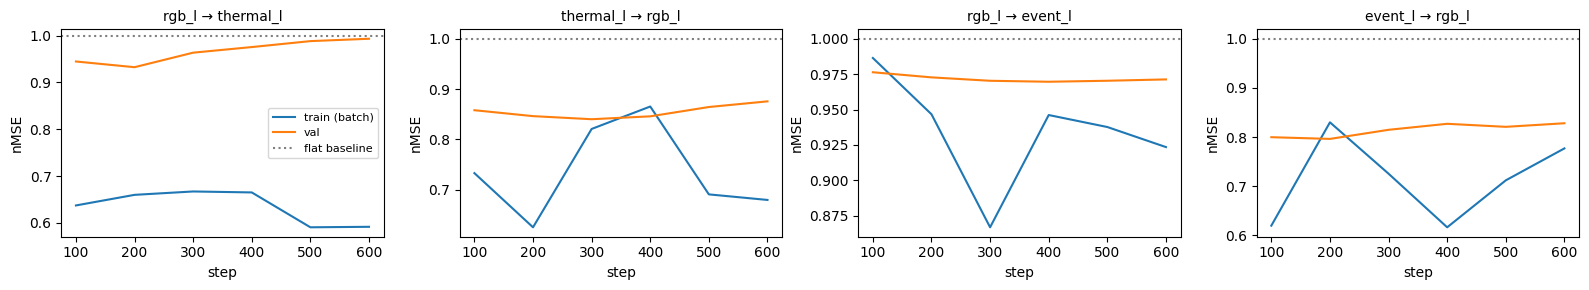

In [14]:
fig, axes = plt.subplots(1, len(ft_logs), figsize=(4 * len(ft_logs), 3), squeeze=False)
for ax, ((src, tgt), lg) in zip(axes[0], ft_logs.items()):
    ax.plot(lg.step, lg.train, label="train (batch)"); ax.plot(lg.step, lg.val, label="val")
    ax.axhline(1.0, ls=":", c="gray", label="flat baseline")
    ax.set_title(f"{src} → {tgt}", fontsize=10); ax.set_xlabel("step"); ax.set_ylabel("nMSE")
axes[0][0].legend(fontsize=8); plt.tight_layout(); plt.show()

## Results

In [15]:
table = pd.DataFrame(results).drop(columns="part").set_index("experiment").round(3)
table

,nMSE (seq mean),± std over seqs,val seqs,val clips,Clear,Fog,Heavy_Rain,Heavy_Snow,Light_Rain,Light_Snow
experiment,,,,,,,,,,
rgb_l tube-mask 75%,0.421,0.172,12,65,0.415,0.309,0.539,0.344,0.436,0.484
rgb_l tube-mask 90%,0.575,0.225,12,65,0.558,0.412,0.734,0.368,0.647,0.734
thermal_l tube-mask 75%,0.481,0.093,12,65,0.382,0.400,0.526,0.615,0.429,0.536
thermal_l tube-mask 90%,0.627,0.077,12,65,0.577,0.512,0.676,0.686,0.595,0.716
event_l tube-mask 75%,0.853,0.062,12,65,0.864,0.830,0.864,0.900,0.840,0.820
event_l tube-mask 90%,0.903,0.059,12,65,0.911,0.900,0.934,0.908,0.901,0.863
rgb_l → thermal_l [flat baseline],0.998,0.000,12,65,0.998,0.998,0.998,0.998,0.998,0.998
rgb_l → thermal_l [copy baseline],2.005,0.415,12,65,1.817,2.203,1.973,1.655,2.441,1.939
rgb_l → thermal_l [copy-inverted baseline],1.731,0.316,12,65,1.793,1.633,2.018,1.338,1.551,2.052


## Look at reconstructions
Middle frame of a few val clips. **Structure only** shows the prediction as the model produces it: per-patch normalized and placed on mid-gray, with no ground-truth information. **With GT patch stats** rescales each predicted patch to the true patch's mean and contrast. That's the usual MAE visualization, but it leaks the target's coarse brightness, so it flatters every model, especially across cameras.

In [16]:
@torch.no_grad()
def recon_images(model, x, mask):
    pred = run(model, x, mask).float().reshape(-1, TS * PS * PS, 3)
    p = patchify(x); mu, sd = patch_stats(p)
    m = mask.to(x.device)
    shown_in = p.clone(); shown_in[m] = 0.5
    structure = p.clone(); structure[m] = (0.5 + 0.15 * pred).clamp(0, 1)
    with_gt = p.clone(); with_gt[m] = pred * sd[m] + mu[m]
    return [unpatchify(t).clamp(0, 1) for t in (shown_in, structure, with_gt, x)]

def show(model, title, mode, n=3, **kw):
    mods = [kw["mod"]] if mode == "self" else [kw["src"], kw["tgt"]]
    seqs = selected["val"][:: max(1, len(selected["val"]) // n)][:n]     # already cached by evaluation
    cs = [store.get(q, mods, "visualization") for q in seqs]
    keep = [(q, c) for q, c in zip(seqs, cs) if len(c[mods[0]])]
    seqs, n = [q for q, _ in keep], len(keep)
    mid = {m: np.stack([c[m][len(c[m]) // 2] for _, c in keep]) for m in mods}
    x = make_x(mid, np.arange(n), mode, kw.get("mod"), kw.get("src"), kw.get("tgt"))
    mask = tube_mask(n, kw.get("ratio", 0.9), torch.Generator().manual_seed(1)) if mode == "self" else bottom_half_mask(n)
    ims = recon_images(model, x, mask)
    cols = ["masked input", "prediction (structure only)", "prediction (with GT patch stats)", "ground truth"]
    fig, axes = plt.subplots(n, 4, figsize=(13, 3.2 * n), squeeze=False)
    for r in range(n):
        for c in range(4):
            axes[r][c].imshow(ims[c][r, CLIP_LEN // 2].permute(1, 2, 0).cpu().numpy()); axes[r][c].axis("off")
            if r == 0: axes[r][c].set_title(cols[c], fontsize=9)
        axes[r][0].text(-5, 112, seqs[r].split("/")[0], rotation=90, va="center", ha="right", fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()

for mod in MODALITIES:
    show(base, f"A. {mod}, 90% tube mask, pretrained", "self", mod=mod, ratio=0.9)
for (src, tgt), mdl in ft_models.items():
    show(base, f"B. {src} → {tgt}, zero-shot (top half visible, bottom half hidden)", "cross", src=src, tgt=tgt)
    mdl.to(DEVICE)
    show(mdl, f"B. {src} → {tgt}, fine-tuned", "cross", src=src, tgt=tgt)
    mdl.cpu()

RuntimeError: shape '[3, 8, 14, 14, 2, 16, 16, 224]' is invalid for input of size 7225344

## What was streamed
Each row is one sequence and camera set fetched from Hugging Face, and the step that first needed it. Everything else came from the disk cache.

In [ ]:
log = pd.DataFrame(store.log)
print(f"{len(log)} streams, {log.seconds.sum() if len(log) else 0:.0f}s total; "
      f"{len(set(log.sequence)) if len(log) else 0} of {len(selected['train']) + len(selected['val'])} selected sequences touched")
log

## Reading the results

- **nMSE scale.** 1.0 means no better than a flat patch. Within one camera, VideoMAE usually lands well below 1 on RGB. Thermal and event show how far its RGB-only pretraining transfers. Event frames are sparse: empty patches have nothing to predict, and patches with a few events are hard, so event scores aren't directly comparable with RGB and thermal.
- **Zero-shot across cameras** should sit near or above the flat baseline. The pretrained model has never seen a hidden half that's a *different sensor*, so it tends to extend the visible half's look downward. That's the expected result: masked reconstruction across modalities isn't something VideoMAE does out of the box.
- **Fine-tuned across cameras** is the real measure of whether one camera predicts the other's structure. Compare it with **copy**. Beating copy means the model learned more than "same edges in the same place". If copy is already strong, the cameras are well aligned after rectification. If it's weak, they differ in field of view, and the model has to learn a fixed geometric offset. You could warp with the calibration in `label.pkl` to remove that.
- **Small sample.** The defaults (2 val sequences per weather, 8 clips each, 600 steps) check the setup works. Clips within a sequence are correlated, so look at **± std over seqs**. For real numbers, raise `SEQ_PER_WEATHER`, `MAX_CLIPS_PER_SEQ` and `FT_STEPS`.
- **Extensions.** (1) Mask only part of the target, with the source visible vs. blanked, to measure how much the other camera *helps* rather than replaces. (2) Fine-tune one model that rebuilds any hidden camera from the others: add a learned modality embedding per half so the model knows which sensor to produce, as multi-modal MAEs like MultiMAE do.